# Case file 9 · The Interrogation: how good is the model, honestly?

<a href="https://colab.research.google.com/github/umanets/pixelsprite/blob/main/learn/08_interrogate.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Four questions, four measurements, on sprites the model never saw (the official validation split):
1. How surprised is the model by real sprites? (bits)  2. Does it obey colour words? (named-colour test)
3. Can a simple detective tell its drawings from real ones? (ROC AUC)  4. Does it understand *combinations*?

**Time:** about 5 minutes on a laptop CPU. **You will learn:** likelihood in bits, teacher forcing for evaluation,
a classifier as a "realism judge", the ROC curve and AUC, and a compositionality test.

In [1]:
try:
    import pixelsprite
except ImportError:
    %pip -q install "pixelsprite[learn] @ git+https://github.com/umanets/pixelsprite"
import os, warnings
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore")
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
import math
import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from pixelsprite import SpritePipeline, sheet, sample, rgba_from_index
from pixelsprite.colour import srgb_to_oklab, to_index
from pixelsprite.data import load_shard
from pixelsprite.model import edge_flags

pipe = SpritePipeline.from_pretrained()
model, palette, dev = pipe.model, pipe.palette, pipe.device
val = load_shard(n=512, shard="data/validation-000.parquet", seed=0)      # never used in training
index = to_index(val.rgba, palette)                                       # snap colours to the model's palette
print(len(val), "validation sprites; palette", palette.shape)

512 validation sprites; palette (1024, 3)


## 1. Bits: the model's surprise at real sprites
**Teacher forcing**: show the model the true pixels one by one and add up −log₂ p(true pixel). A perfect
predictor would pay 0 bits; a model that knows nothing about pictures pays log₂(1025) ≈ 10 bits per pixel,
2,560 per sprite. We compare "with caption" and "without caption": the difference is what the words are worth.

In [3]:
@torch.no_grad()
def bits_per_sprite(idx, captions):
    b = len(idx)
    flat = torch.as_tensor(idx.reshape(b, -1))
    tgt = torch.where(flat < 0, torch.full_like(flat, model.EMPTY), flat).to(dev)
    prev = torch.cat([torch.full((b, 1), model.BOS, device=dev), tgt[:, :-1]], 1)
    ar = torch.arange(256, device=dev)
    rows, cols = (ar // 16).expand(b, -1), (ar % 16).expand(b, -1)
    known = torch.zeros(b, dtype=torch.bool, device=dev)
    mask = torch.zeros(b, 16, 16, dtype=torch.bool, device=dev)
    cond = model.cond(pipe.embed(captions).to(dev)) if captions else model.cond(None, batch=b)
    logits = model(cond, 16, mask, known, prev, rows, cols, edge_flags(mask, known)).float()
    nll = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), tgt.reshape(-1), reduction="none").view(b, -1)
    return (nll.sum(1) / math.log(2)).cpu().numpy()

with_text = np.concatenate([bits_per_sprite(index[i:i + 64], val.caption[i:i + 64]) for i in range(0, 256, 64)])
no_text = np.concatenate([bits_per_sprite(index[i:i + 64], None) for i in range(0, 256, 64)])
print(f"with caption: {with_text.mean():.0f} bits per sprite; without: {no_text.mean():.0f}; the words are worth "
      f"{(no_text - with_text).mean():.0f} bits")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4199.64it/s]

with caption: 324 bits per sprite; without: 356; the words are worth 33 bits


## 2. The named-colour test
Take validation captions that name exactly one basic colour, draw one sprite per caption, and check whether that
colour is the dominant hue. Real sprites with the same captions give the ceiling.

In [4]:
PROTOS = {"red": (220, 40, 40), "orange": (240, 140, 30), "yellow": (240, 215, 50), "green": (60, 170, 60),
          "cyan": (40, 190, 200), "blue": (40, 90, 220), "purple": (140, 60, 200), "pink": (240, 120, 180)}
proto_hue = np.array([np.arctan2(*srgb_to_oklab(np.array(v, np.uint8))[[2, 1]]) for v in PROTOS.values()])
NAMES = list(PROTOS)

def dominant_hue(rgba):
    m = rgba[..., 3] > 0
    p = np.pad(m, 1); inner = m & p[:-2, 1:-1] & p[2:, 1:-1] & p[1:-1, :-2] & p[1:-1, 2:]
    lab = srgb_to_oklab(rgba[inner if inner.any() else m][:, :3])
    hue = np.arctan2(lab[:, 2], lab[:, 1])[np.hypot(lab[:, 1], lab[:, 2]) >= 0.05]
    if len(hue) == 0:
        return "grey"
    d = np.abs(np.angle(np.exp(1j * (hue[:, None] - proto_hue))))
    return NAMES[np.bincount(d.argmin(1), minlength=len(NAMES)).argmax()]

named = [(i, [w for w in NAMES if w in c.lower().split()]) for i, c in enumerate(val.caption)]
named = [(i, ws[0]) for i, ws in named if len(ws) == 1][:60]
real_hits = [dominant_hue(val.rgba[i]) == w for i, w in named]
def draw_for(captions, seed):
    """One sprite per caption in a single batched call (default settings: shape 1, colour 2)."""
    idx, _ = sample(model, len(captions), pipe.embed(captions), size=16, seed=seed, chunk=32)
    return [rgba_from_index(x, palette) for x in idx]

gen = draw_for([val.caption[i] for i, _ in named], seed=1)
gen_hits = [dominant_hue(s) == w for s, (_, w) in zip(gen, named)]
print(f"{len(named)} captions: named colour dominant in {100 * np.mean(gen_hits):.0f}% of model sprites, "
      f"{100 * np.mean(real_hits):.0f}% of real ones")

60 captions: named colour dominant in 88% of model sprites, 78% of real ones


## 3. A realism judge and the ROC curve
We describe each sprite with a few numbers (area, outline length, colour count, brightness…) and train a simple
classifier (logistic regression) to tell real from generated. **AUC** = the chance that the judge gives a random
generated sprite a higher "fake" score than a random real one. 0.5 means it is guessing; 1.0 means it always knows.

AUC = 0.50


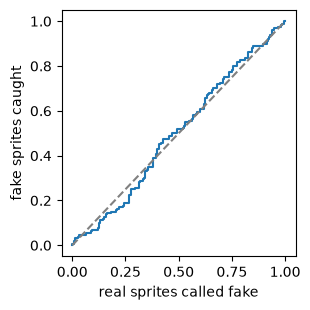

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve

def features(rgba):
    m = rgba[..., 3] > 0
    p = np.pad(m, 1).astype(int)
    perim = np.abs(np.diff(p, axis=0)).sum() + np.abs(np.diff(p, axis=1)).sum()
    lab = srgb_to_oklab(rgba[m][:, :3])
    return [m.sum(), perim / math.sqrt(m.sum()), len(np.unique(rgba[m][:, :3], axis=0)), lab[:, 0].mean(),
            lab[:, 0].std(), np.hypot(lab[:, 1], lab[:, 2]).mean(), (m == m[:, ::-1]).mean()]

real = [val.rgba[i] for i in range(160)]
fake = draw_for(val.caption[160:320], seed=2)            # drawn from other validation captions
X = np.array([features(s) for s in real + fake]); y = np.r_[np.zeros(len(real)), np.ones(len(fake))]
score = cross_val_predict(LogisticRegression(max_iter=2000), (X - X.mean(0)) / X.std(0), y, cv=5, method="predict_proba")[:, 1]
fpr, tpr, _ = roc_curve(y, score)
print(f"AUC = {roc_auc_score(y, score):.2f}")
plt.figure(figsize=(3.2, 3.2)); plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], "--", c="grey")
plt.xlabel("real sprites called fake"); plt.ylabel("fake sprites caught"); plt.tight_layout(); plt.show()

## 4. Do words combine?
Single words work. What about two attributes at once? We measure the share of blue and of warm (fire-coloured)
pixels for three captions.

blue mushroom         : blue   94% of coloured pixels, fire colours    1%


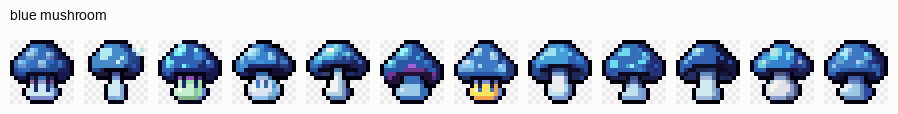

flaming mushroom      : blue    2% of coloured pixels, fire colours   92%


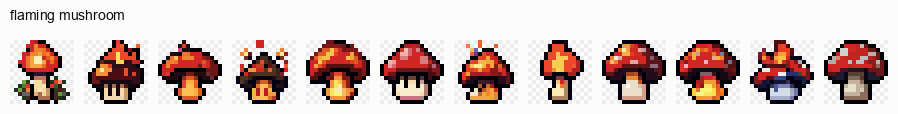

blue flaming mushroom : blue   88% of coloured pixels, fire colours    4%


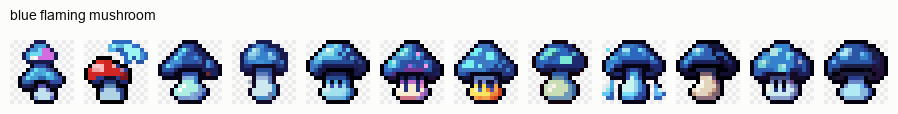

In [6]:
def shares(sprites):
    lab = np.concatenate([srgb_to_oklab(s[s[..., 3] > 0][:, :3]) for s in sprites])
    hue = np.arctan2(lab[:, 2], lab[:, 1]); ok = np.hypot(lab[:, 1], lab[:, 2]) >= 0.05
    d = np.abs(np.angle(np.exp(1j * (hue[ok][:, None] - proto_hue)))).argmin(1)
    names = np.array(NAMES)[d]
    return np.isin(names, ["blue", "cyan"]).mean(), np.isin(names, ["red", "orange", "yellow"]).mean()

for text in ["blue mushroom", "flaming mushroom", "blue flaming mushroom"]:
    res = pipe.generate(text, 16, 16, seed=5)
    b, w = shares(res.sprites)
    print(f"{text:22}: blue {100 * b:4.0f}% of coloured pixels, fire colours {100 * w:4.0f}%")
    display(sheet(res.sprites[:12], text, scale=4, cols=12))

## Your turn
1. Repeat section 1 for captions translated to Russian. How many bits do the words save now?
2. Add a feature to the realism judge that you think gives the model away. Does the AUC go up?
3. Try other pairs: "golden frozen crown", "red crystal sword". Which word wins?